# M09 · Árbol de decisión

Modelo de árbol de la fase 2. Usamos el preprocesado y la evaluación comunes de `src/modeling.py`, para que todos los modelos se comparen igual.

**Reglas del equipo (EDA, paso 14.4):**
- Solo `train`. El test no se toca hasta M08.
- Validación cruzada con `StratifiedGroupKFold` agrupando por `grupo_producto`.
- Métrica principal: **F1 macro**, con recall por clase (sobre todo NOVA 2). Objetivo: gap train/CV < 0,05.
- Imputación dentro del pipeline, ajustada solo con el train de cada fold.
- Sin `log1p` ni escalado: los árboles cortan por umbrales, así que no les afecta la escala.

**Experimentos:**
1. Árbol sin límite de profundidad (para ver el sobreajuste).
2. Barrido de `max_depth`.
3. Con `class_weight="balanced"`.
4. Con y sin `tiene_potenciadores`.

In [1]:
import sys
sys.path.insert(0, "..")

import json
import platform

import joblib
import matplotlib.pyplot as plt
import pandas as pd
import sklearn
from sklearn.dummy import DummyClassifier
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier, plot_tree

# Funciones y constantes comunes del equipo
from src.modeling import (TARGET, GROUP, LABELS, load_train, get_feature_columns, build_preprocessor, evaluate_cv, MODELS_DIR, REPORTS_DIR)

In [2]:
df = load_train()
print(df.shape)
print(df[TARGET].value_counts(normalize=True).sort_index().round(3))

y, groups = df[TARGET], df[GROUP]

(38495, 35)
nova_group
1    0.129
2    0.112
3    0.204
4    0.555
Name: proportion, dtype: float64


## Función auxiliar

Un solo sitio para construir y evaluar cada variante. Guardamos los resultados en un diccionario para compararlos al final.

In [3]:
results = {}

def run(name, max_depth=None, class_weight=None, drop=()):
    cols = get_feature_columns(df, drop=drop)
    model = Pipeline([
        # Sin log ni escalado: solo imputación + one-hot de la categoría
        ("prep", build_preprocessor(cols, log_skewed=False, scale=False)),
        # Random_state fijo: si dos cortes empatan, el árbol elige siempre el mismo
        ("clf", DecisionTreeClassifier(max_depth=max_depth, class_weight=class_weight, random_state=42)),
    ])
    res = evaluate_cv(model, df[cols["all"]], y, groups)
    results[name] = res
    print(f"{name}: F1 train {res['f1_macro_train']}, F1 CV {res['f1_macro_cv']} "
              f"(±{res['f1_macro_cv_std']}), gap {res['gap']}, recall {res['recall']}")
    return res

## 0. Suelo: `DummyClassifier`

Un modelo que dice siempre la clase más frecuente (NOVA 4). Es la referencia que todos los modelos deben superar.

In [4]:
cols_all = get_feature_columns(df)
res = evaluate_cv(DummyClassifier(strategy="most_frequent"), df[cols_all["all"]], y, groups)
results["0 dummy (siempre NOVA 4)"] = res
print(f"0 dummy: F1 macro CV {res['f1_macro_cv']}, recall {res['recall']}")

0 dummy: F1 macro CV 0.1785, recall {'nova_1': 0.0, 'nova_2': 0.0, 'nova_3': 0.0, 'nova_4': 1.0}


**Resultado:** el dummy saca un F1 macro de 0,1785. Acierta todos los NOVA 4 (recall 1) y ninguno del resto (recall 0). Ese es el suelo: cualquier árbol que no lo supere de largo no sirve.

## 1. Árbol sin límite de profundidad

Sin `max_depth`, el árbol sigue dividiendo hasta que cada hoja es pura, así que puede memorizar el train. Esperamos un F1 en train casi perfecto y un gap grande.

In [5]:
run("1 sin límite", max_depth=None);

1 sin límite: F1 train 0.9997, F1 CV 0.941 (±0.0022), gap 0.0587, recall {'nova_1': 0.9402, 'nova_2': 0.9854, 'nova_3': 0.88, 'nova_4': 0.9581}


**Resultado:**

| | F1 train | F1 CV | Gap |
|---|---|---|---|
| Sin límite | 0,9997 | 0,941 (±0,0022) | **0,0587** |

El árbol sin límite acierta prácticamente todo el train, pero en validación baja casi 6 puntos. El gap (0,0587) supera el 5 % que pide el equipo: el árbol está **sobreajustando**. Sigue dividiendo hasta tener hojas puras, así que acaba memorizando productos concretos del train que luego no aparecen en los otros folds (la CV agrupa por `grupo_producto`, así que un producto y sus casi duplicados nunca están a la vez en train y validación).

Por eso hay que limitar `max_depth`.

## 2. Barrido de `max_depth`

Cuanto más profundo, más preguntas puede hacer el árbol: sube el F1 en train, pero a partir de cierto punto el CV deja de mejorar y el gap crece.

In [6]:
DEPTHS = [3, 4, 5, 6, 8, 10, 12, 15, 18, 20, 25]

for d in DEPTHS:
    run(f"2 depth={d}", max_depth=d)

2 depth=3: F1 train 0.7911, F1 CV 0.791 (±0.0064), gap 0.0, recall {'nova_1': 0.7007, 'nova_2': 0.8579, 'nova_3': 0.6783, 'nova_4': 0.8687}
2 depth=4: F1 train 0.8324, F1 CV 0.8323 (±0.0058), gap 0.0001, recall {'nova_1': 0.7005, 'nova_2': 0.9208, 'nova_3': 0.6783, 'nova_4': 0.9463}
2 depth=5: F1 train 0.8571, F1 CV 0.8548 (±0.0052), gap 0.0022, recall {'nova_1': 0.8417, 'nova_2': 0.9485, 'nova_3': 0.8586, 'nova_4': 0.859}
2 depth=6: F1 train 0.8936, F1 CV 0.8923 (±0.0045), gap 0.0013, recall {'nova_1': 0.9475, 'nova_2': 0.948, 'nova_3': 0.8479, 'nova_4': 0.8997}
2 depth=8: F1 train 0.9246, F1 CV 0.9213 (±0.0067), gap 0.0033, recall {'nova_1': 0.9792, 'nova_2': 0.9596, 'nova_3': 0.8617, 'nova_4': 0.9327}
2 depth=10: F1 train 0.9407, F1 CV 0.9335 (±0.0024), gap 0.0072, recall {'nova_1': 0.979, 'nova_2': 0.9652, 'nova_3': 0.8988, 'nova_4': 0.9377}
2 depth=12: F1 train 0.9521, F1 CV 0.9393 (±0.0012), gap 0.0128, recall {'nova_1': 0.9849, 'nova_2': 0.9775, 'nova_3': 0.8969, 'nova_4': 0.944

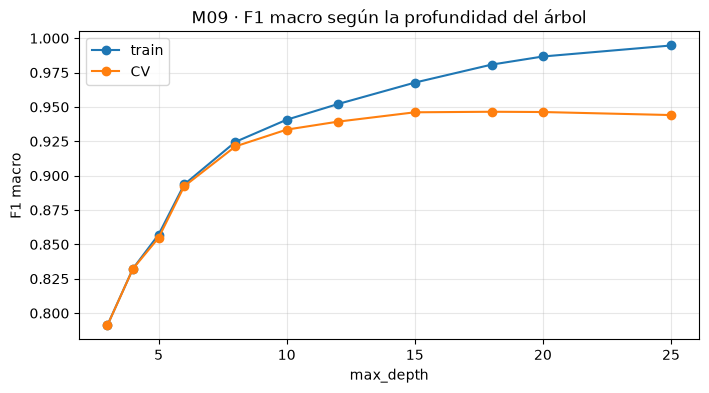

In [7]:
# Sacamos del diccionario los F1 de cada profundidad
f1_train = [results[f"2 depth={d}"]["f1_macro_train"] for d in DEPTHS]
f1_cv = [results[f"2 depth={d}"]["f1_macro_cv"] for d in DEPTHS]

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(DEPTHS, f1_train, marker="o", label="train")
ax.plot(DEPTHS, f1_cv, marker="o", label="CV")
ax.set_xlabel("max_depth")
ax.set_ylabel("F1 macro")
ax.set_title("M09 · F1 macro según la profundidad del árbol")
ax.legend()
ax.grid(alpha=0.3)
plt.show()

**Resultado:**

| max_depth | F1 train | F1 CV | Gap |
|---|---|---|---|
| 3 | 0,791 | 0,791 | 0,000 |
| 6 | 0,894 | 0,892 | 0,001 |
| 10 | 0,941 | 0,934 | 0,007 |
| 12 | 0,952 | 0,939 | 0,013 |
| 15 | 0,968 | 0,946 | 0,022 |
| 18 | 0,981 | 0,946 | 0,035 |
| 20 | 0,987 | 0,946 | 0,041 |
| 25 | 0,995 | 0,944 | **0,051** |

Cómo leer la curva:
- **Hasta una profundidad de 10**, train y CV suben juntos: cada nivel nuevo aprende reglas que sirven para productos que no ha visto.
- **A partir de 15**, el CV se queda plano en ~0,946 y el train sigue subiendo. Los niveles extra ya no aprenden reglas generales, solo memorizan.
- **Con una profundidad de 25** el gap ya supera el 5 %. El límite útil está entre 15 y 20.

## 3. Con `class_weight="balanced"`

Da más peso a las clases pequeñas (NOVA 4 es el 55 %). Lo probamos en las profundidades donde el F1 CV ya es alto.

In [8]:
for d in [8, 10, 12, 15, 18, 20]:
    run(f"3 balanced, depth={d}", max_depth=d, class_weight="balanced")

3 balanced, depth=8: F1 train 0.9153, F1 CV 0.9131 (±0.0053), gap 0.0022, recall {'nova_1': 0.997, 'nova_2': 0.9464, 'nova_3': 0.9113, 'nova_4': 0.8986}
3 balanced, depth=10: F1 train 0.9342, F1 CV 0.9286 (±0.0032), gap 0.0056, recall {'nova_1': 0.9842, 'nova_2': 0.9742, 'nova_3': 0.9338, 'nova_4': 0.9102}
3 balanced, depth=12: F1 train 0.9458, F1 CV 0.9379 (±0.0028), gap 0.008, recall {'nova_1': 0.9836, 'nova_2': 0.9831, 'nova_3': 0.9395, 'nova_4': 0.9213}
3 balanced, depth=15: F1 train 0.9571, F1 CV 0.9436 (±0.0027), gap 0.0134, recall {'nova_1': 0.9838, 'nova_2': 0.9842, 'nova_3': 0.9352, 'nova_4': 0.933}
3 balanced, depth=18: F1 train 0.9678, F1 CV 0.9482 (±0.0019), gap 0.0197, recall {'nova_1': 0.9798, 'nova_2': 0.9835, 'nova_3': 0.9353, 'nova_4': 0.9409}
3 balanced, depth=20: F1 train 0.9744, F1 CV 0.9496 (±0.0028), gap 0.0248, recall {'nova_1': 0.9756, 'nova_2': 0.9854, 'nova_3': 0.9278, 'nova_4': 0.947}


**Resultado:**

| max_depth | F1 train | F1 CV (balanced) | Gap (balanced) | F1 CV (sin peso) | Gap (sin peso) | Recall NOVA 3 (sin peso → balanced) | Recall NOVA 4 (sin peso → balanced) |
|---|---|---|---|---|---|---|---|
| 8 | 0,9153 | 0,9131 (±0,0053) | 0,0022 | 0,9213 | 0,0033 | 0,86 → 0,91 | 0,93 → 0,90 |
| 10 | 0,9342 | 0,9286 (±0,0032) | 0,0056 | 0,9335 | 0,0072 | 0,90 → 0,93 | 0,94 → 0,91 |
| 12 | 0,9458 | 0,9379 (±0,0028) | 0,0080 | 0,9393 | 0,0128 | 0,90 → 0,94 | 0,94 → 0,92 |
| 15 | 0,9571 | 0,9436 (±0,0027) | 0,0134 | 0,9461 | 0,0216 | 0,90 → 0,94 | 0,95 → 0,93 |
| 18 | 0,9678 | 0,9482 (±0,0019) | 0,0197 | 0,9462 | 0,0346 | 0,89 → 0,94 | 0,95 → 0,94 |
| 20 | 0,9744 | 0,9496 (±0,0028) | 0,0248 | 0,9462 | 0,0405 | 0,89 → 0,93 | 0,96 → 0,95 |

Qué vemos:
- **El gap es más pequeño con `balanced` en todas las profundidades.** Al pesar más las clases pequeñas, el árbol no dedica tantas divisiones a afinar NOVA 4, que es la mayoritaria. Por eso sobreajusta menos.
- **El recall de NOVA 3 sube entre 3 y 5 puntos**, y es la clase que más le cuesta al árbol. A cambio baja algo el de NOVA 4. Es el intercambio esperado: deja de favorecer a la clase grande.
- **NOVA 1 y NOVA 2 se quedan por encima de 0,97** a partir de una profundidad de 10, con y sin pesos.
- **En F1 CV, hasta 15 gana el árbol sin pesos. A partir de 18 gana `balanced`**: con poca profundidad, dar peso a las clases pequeñas obliga a sacrificar NOVA 4 sin tener ramas suficientes para compensarlo. Con más profundidad hay espacio para las dos cosas.
- Entre 18 y 20 con `balanced`, la diferencia de F1 CV (0,0014) es **menor que la std entre folds** (~0,002-0,003), así que en la práctica están empatadas.